In [51]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

from sklearn.linear_model import Perceptron
from sklearn.metrics import accuracy_score,classification_report,confusion_matrix

from tensorflow.keras.models import Sequential
import tensorflow as tf
from tensorflow.keras.layers import Dense
from tensorflow.keras.layers import Conv2D
from tensorflow.keras.layers import Flatten

from tensorflow.keras.layers import MaxPooling2D
from tensorflow.keras.layers import Dropout

from tensorflow.keras.utils import to_categorical

In [52]:
df=pd.read_csv('digits_train.csv')
df_test=pd.read_csv('digits_test.csv')

In [53]:
df.head()

,label,pixel0,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,...,pixel54,pixel55,pixel56,pixel57,pixel58,pixel59,pixel60,pixel61,pixel62,pixel63
0,5,0.0,0.0,11.0,10.0,12.0,14.0,11.0,0.0,0.0,...,0.0,0.0,0.0,0.0,9.0,14.0,9.0,2.0,0.0,0.0
1,0,0.0,0.0,2.0,13.0,15.0,7.0,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,3.0,14.0,14.0,1.0,0.0,0.0
2,5,0.0,1.0,15.0,16.0,16.0,16.0,5.0,0.0,0.0,...,0.0,0.0,0.0,3.0,15.0,16.0,6.0,0.0,0.0,0.0
3,7,0.0,0.0,5.0,16.0,12.0,2.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,6.0,11.0,0.0,0.0,0.0,0.0
4,1,0.0,0.0,0.0,0.0,5.0,14.0,3.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,5.0,13.0,4.0,0.0


In [54]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1437 entries, 0 to 1436
Data columns (total 65 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   label    1437 non-null   int64  
 1   pixel0   1437 non-null   float64
 2   pixel1   1437 non-null   float64
 3   pixel2   1437 non-null   float64
 4   pixel3   1437 non-null   float64
 5   pixel4   1437 non-null   float64
 6   pixel5   1437 non-null   float64
 7   pixel6   1437 non-null   float64
 8   pixel7   1437 non-null   float64
 9   pixel8   1437 non-null   float64
 10  pixel9   1437 non-null   float64
 11  pixel10  1437 non-null   float64
 12  pixel11  1437 non-null   float64
 13  pixel12  1437 non-null   float64
 14  pixel13  1437 non-null   float64
 15  pixel14  1437 non-null   float64
 16  pixel15  1437 non-null   float64
 17  pixel16  1437 non-null   float64
 18  pixel17  1437 non-null   float64
 19  pixel18  1437 non-null   float64
 20  pixel19  1437 non-null   float64
 21  pixel20  1437 

In [55]:
df.shape

(1437, 65)

In [56]:
df.isnull().sum()

,0
label,0
pixel0,0
pixel1,0
pixel2,0
pixel3,0
...,...
pixel59,0
pixel60,0
pixel61,0
pixel62,0


In [57]:
X_train = df.drop('label', axis=1).values
y_train= df['label'].values
X_test=df_test.drop("label",axis=1).values
y_test=df_test["label"].values

In [58]:
X_train = X_train.astype("float32") / 16.0
X_test = X_test.astype("float32") / 16.0

X_train_img = X_train.reshape(-1, 8, 8)
X_test_img = X_test.reshape(-1, 8, 8)

In [59]:
y_train_cat=to_categorical(y_train,10)
y_test_cat=to_categorical(y_test,10)


In [60]:
perceptron=Sequential([
    Flatten(input_shape=(8,8)),
    Dense(10,activation="relu")
])

In [61]:
perceptron.compile(
    optimizer="sgd",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

In [62]:
history_precp=perceptron.fit(
    X_train_img,
    y_train_cat,
    epochs=10,
    validation_data=(X_test_img,y_test_cat),verbose=1
)

Epoch 1/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.1649 - loss: 5.8140 - val_accuracy: 0.2528 - val_loss: 4.2372
Epoch 2/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.3090 - loss: 3.4138 - val_accuracy: 0.4306 - val_loss: 3.1411
Epoch 3/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.3848 - loss: 3.1074 - val_accuracy: 0.5111 - val_loss: 2.8994
Epoch 4/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.3466 - loss: 3.0381 - val_accuracy: 0.1222 - val_loss: 2.9567
Epoch 5/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.3793 - loss: 2.8892 - val_accuracy: 0.6639 - val_loss: 2.5462
Epoch 6/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.3619 - loss: nan - val_accuracy: 0.1000 - val_loss: nan
Epoch 7/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.0988 - loss: nan - val_accuracy: 0.1000 - val_loss: nan
Epoch 8/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.0988 - loss: nan - val_accuracy: 0.1000 - val_loss: nan
Epoch 9/10

In [63]:

acc_precp=perceptron.evaluate(X_test_img,y_test_cat,verbose=0)[1]

In [64]:
acc_precp

0.10000000149011612

In [65]:
ann=Sequential([
    Flatten(input_shape=(8,8)),
    Dense(128,activation="relu"),
    Dense(64,activation="relu"),
    Dense(10,activation="softmax")
])

In [66]:
ann.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

In [67]:
history_ann=ann.fit(
    X_train_img,
    y_train_cat,
    epochs=100,
    validation_data=(X_test_img,y_test_cat),verbose=1
)

Epoch 1/100
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.5198 - loss: 1.8292 - val_accuracy: 0.7194 - val_loss: 1.2804
Epoch 2/100
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8504 - loss: 0.8469 - val_accuracy: 0.8889 - val_loss: 0.5444
Epoch 3/100
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9235 - loss: 0.4064 - val_accuracy: 0.9278 - val_loss: 0.3079
Epoch 4/100
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9415 - loss: 0.2635 - val_accuracy: 0.9583 - val_loss: 0.2097
Epoch 5/100
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9617 - loss: 0.1870 - val_accuracy: 0.9722 - val_loss: 0.1654
Epoch 6/100
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9694 - loss: 0.1461 - val_accuracy: 0.9750 - val_loss: 0.1411
Epoch 7/100
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9743 - loss: 0.1230 - val_accuracy: 0.9806 - val_loss: 0.1281
Epoch 8/100
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9784 - loss: 0.1060 - val_accuracy: 0.9722 - v

In [94]:
ann_precp=ann.evaluate(X_test_img,y_test_cat,verbose=0)[1]

In [95]:
ann_precp

0.9861111044883728

In [96]:
#CNN

In [97]:
X_train_cnn = X_train.reshape(-1, 8, 8,1)
X_test_cnn = X_test.reshape(-1, 8, 8,1)

In [98]:
cnn = Sequential([
    Conv2D(32, kernel_size=(3,3), activation="relu", padding="same", input_shape=(8,8,1)),
    MaxPooling2D((2,2)),          # 8x8 -> 4x4
    Conv2D(64, kernel_size=(3,3), activation="relu", padding="same"),
    MaxPooling2D((2,2)),          # 4x4 -> 2x2
    Flatten(),
    Dense(128, activation="relu"),
    Dropout(0.5),
    Dense(10, activation="softmax")
])

In [99]:
cnn.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

In [100]:
history_cnn=cnn.fit(
    X_train_cnn,
    y_train_cat,
    epochs=15,
    validation_data=(X_test_cnn,y_test_cat),verbose=1
)

Epoch 1/15
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.3041 - loss: 2.1512 - val_accuracy: 0.7389 - val_loss: 1.7939
Epoch 2/15
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.6569 - loss: 1.3195 - val_accuracy: 0.7806 - val_loss: 0.7542
Epoch 3/15
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.8156 - loss: 0.6614 - val_accuracy: 0.9083 - val_loss: 0.3840
Epoch 4/15
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.8775 - loss: 0.4255 - val_accuracy: 0.9528 - val_loss: 0.1879
Epoch 5/15
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.9033 - loss: 0.3192 - val_accuracy: 0.9528 - val_loss: 0.1803
Epoch 6/15
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.9255 - loss: 0.2331 - val_accuracy: 0.9500 - val_loss: 0.1597
Epoch 7/15
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9485 - loss: 0.1801 - val_accuracy: 0.9722 - val_loss: 0.0997
Epoch 8/15
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9457 - loss: 0.1759 - val_accuracy: 0.9833 - val_loss

In [101]:
acc_cnn=cnn.evaluate(X_test_cnn,y_test_cat,verbose=0)[1]

In [102]:
acc_cnn

0.980555534362793

In [103]:
def show_side_by_side(models, model_names, X, X_cnn, y_true, n=5):
    idxs = np.random.choice(len(X), n, replace=False)
    plt.figure(figsize=(15, 6))
    for i, idx in enumerate(idxs):
        plt.subplot(2, n, i+1)
        plt.imshow(X[idx].reshape(8, 8), cmap="gray")
        plt.axis("off")
        plt.title(f"True: {y_true[idx]}")
        preds = [np.argmax(model.predict(X_cnn[idx].reshape(1, 8, 8, 1) if name == "CNN" else X[idx].reshape(1, 8, 8)))
                 for model, name in zip(models, model_names)]
        plt.subplot(2, n, n+i+1)
        plt.axis("off")
        plt.title("\n".join(f"{n}: {p}" for n, p in zip(model_names, preds)))
    plt.tight_layout()
    plt.show()


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 85ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step


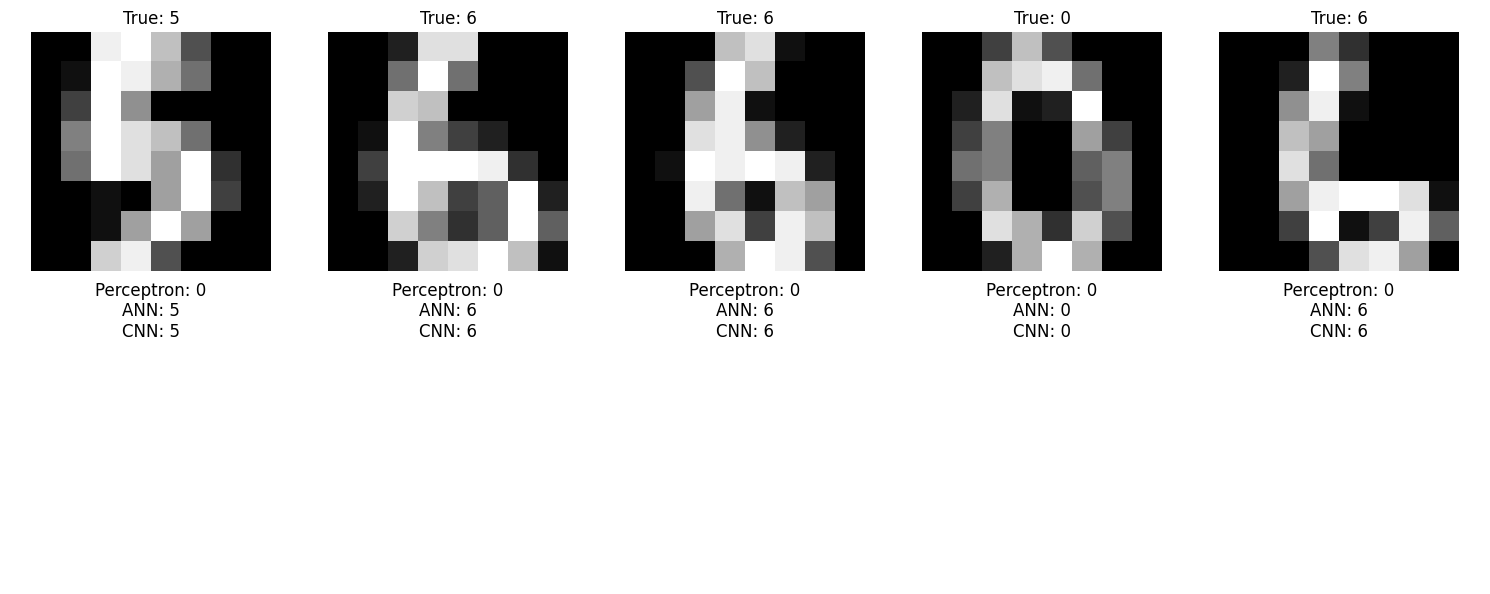

In [104]:
show_side_by_side([perceptron, ann, cnn], ["Perceptron", "ANN", "CNN"], X_test_img, X_test_cnn, y_test, 5)

12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step 


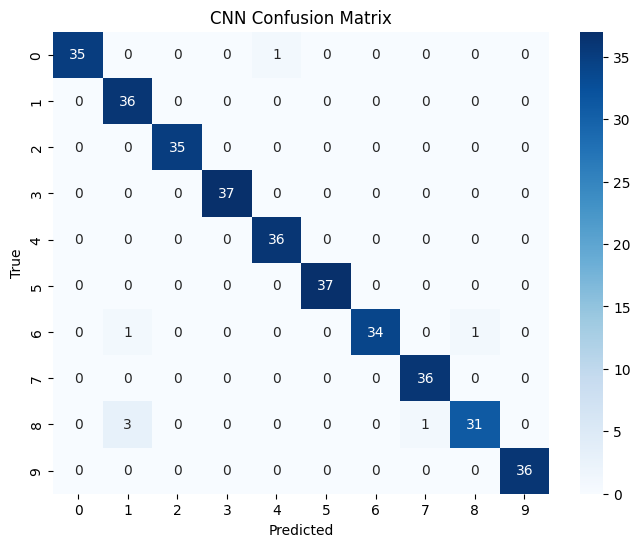

In [105]:
y_pred_cnn = np.argmax(cnn.predict(X_test_cnn), axis=1)
cm = confusion_matrix(y_test, y_pred_cnn)
plt.figure(figsize=(8,6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.title("CNN Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.show()

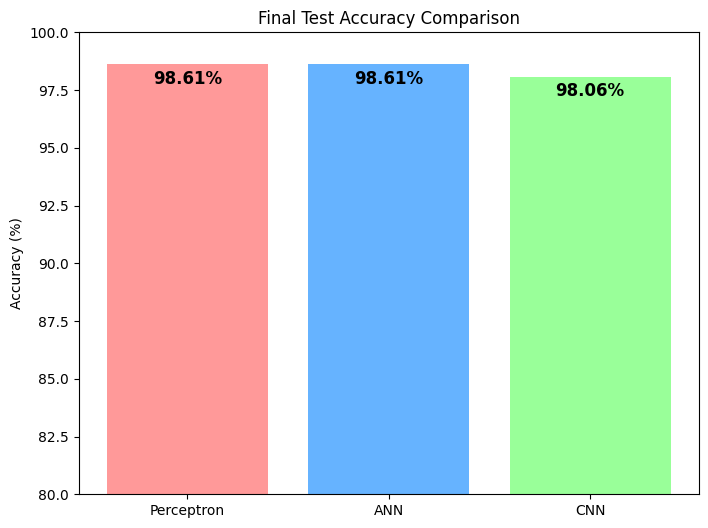

In [107]:
final_accs = [acc_precp*100,ann_precp*100,acc_cnn*100]
models = ["Perceptron", "ANN", "CNN"]

plt.figure(figsize=(8,6))
bars = plt.bar(models, final_accs, color=['#ff9999','#66b3ff','#99ff99'])
plt.title("Final Test Accuracy Comparison")
plt.ylabel("Accuracy (%)")
for bar, acc in zip(bars, final_accs):
    plt.text(bar.get_x()+bar.get_width()/2, bar.get_height()-1, f"{acc:.2f}%",
             ha='center', va='bottom', fontsize=12, fontweight='bold')
plt.ylim(80, 100)
plt.show()